# Large-scale bundle adjustment with piazzi and SE(3) cameras

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cai4cai/torch-piazzi/blob/main/notebooks/bundle_adjustment.ipynb)

This notebook follows the SciPy Cookbook example [Large-scale bundle adjustment in scipy](https://scipy-cookbook.readthedocs.io/items/bundle_adjustment.html) (Nikolay Mayorov, BSD licence), with `piazzi` and PyTorch in place of `scipy.optimize.least_squares`.

Bundle adjustment refines camera parameters and 3D points together, so that the points reprojected into the cameras match the observed 2D features. It is a nonlinear least-squares problem with tens of thousands of parameters, but each residual depends on one camera and one point only, so its Jacobian is very sparse.

Compared with the cookbook, this version:

- stores each camera pose as a 4 x 4 rigid transform and optimises it on SE(3) with `piazzi.SE3`, instead of as a rotation vector plus translation;
- gets the Jacobian from PyTorch autodiff through the manifold's `plus`, instead of finite differences with a sparsity pattern;
- builds the sparse normal equations `J^T J` explicitly and solves them in two ways: with preconditioned conjugate gradients from [torchsparsegradutils](https://github.com/cai4cai/torchsparsegradutils) (generic), and with the Schur complement (which exploits the camera/point structure, as bundle-adjustment solvers such as Ceres do);
- runs the same code on a GPU (CUDA or Apple MPS) in float32, either with only the residuals and Jacobians on the GPU or with the solver there too.

## Setup

On Colab, the next cell installs `piazzi` from GitHub, with the optional `sparse` dependencies (torchsparsegradutils). Locally, install the notebook dependencies with `uv sync --group notebooks` (see the README).

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q "piazzi[sparse] @ git+https://github.com/cai4cai/torch-piazzi"

In [2]:
import bz2
import inspect
import time
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

import piazzi

torch.set_default_dtype(torch.float64)
# torch 2.15 and earlier warn spuriously the first time forward-mode autodiff runs
# (fixed upstream in https://github.com/pytorch/pytorch/pull/203621).
warnings.filterwarnings("ignore", r"`torch\.jit\.script` is deprecated", FutureWarning)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["legend.fontsize"] = 12
plt.rcParams["axes.labelsize"] = 14

## The data

As in the cookbook, we use the "Ladybug" problem with 49 cameras from the [Bundle Adjustment in the Large](https://grail.cs.washington.edu/projects/bal/) (BAL) dataset. Each camera has 9 parameters: a rotation vector $\mathbf{r}$, a translation $\mathbf{t}$, a focal length $f$ and two radial distortion coefficients $k_1, k_2$. A world point $\mathbf{X}$ projects to

$$
\mathbf{P} = R(\mathbf{r})\,\mathbf{X} + \mathbf{t}, \qquad
\mathbf{p} = -\mathbf{P}_{xy} / P_z, \qquad
\mathbf{u} = f\,(1 + k_1 \|\mathbf{p}\|^2 + k_2 \|\mathbf{p}\|^4)\,\mathbf{p}.
$$

The file is downloaded once (about 450 KB) and cached next to the notebook.

In [3]:
URL = "https://grail.cs.washington.edu/projects/bal/data/ladybug/problem-49-7776-pre.txt.bz2"
path = Path(URL.rsplit("/", 1)[1])
if not path.exists():
    urllib.request.urlretrieve(URL, path)


def read_bal_data(path):
    with bz2.open(path, "rt") as f:
        n_cameras, n_points, n_observations = map(int, f.readline().split())
        observations = np.loadtxt(f, max_rows=n_observations)
        params = np.loadtxt(f)
    camera_params = params[: n_cameras * 9].reshape(n_cameras, 9)
    points_3d = params[n_cameras * 9 :].reshape(n_points, 3)
    camera_indices = observations[:, 0].astype(int)
    point_indices = observations[:, 1].astype(int)
    points_2d = observations[:, 2:]
    return camera_params, points_3d, camera_indices, point_indices, points_2d


camera_params, points_3d, camera_indices, point_indices, points_2d = read_bal_data(path)
n_cameras, n_points, n_observations = len(camera_params), len(points_3d), len(points_2d)
print(f"cameras: {n_cameras}, points: {n_points}, observations: {n_observations}")
print(f"parameters (as in the cookbook): {9 * n_cameras + 3 * n_points}, residuals: {2 * n_observations}")

cameras: 49, points: 7776, observations: 31843
parameters (as in the cookbook): 23769, residuals: 63686


## Cameras on SE(3)

Each BAL camera maps world coordinates to camera coordinates, $\mathbf{P} = R\mathbf{X} + \mathbf{t}$. We store this map as a 4 x 4 rigid transform $T = \begin{bmatrix} R & \mathbf{t} \\ 0 & 1 \end{bmatrix}$ and let `piazzi.SE3` keep it rigid during the optimisation, with 6 degrees of freedom per pose.

`piazzi.SE3(side="left")` updates a pose as $T \leftarrow \Delta(\boldsymbol\delta)\,T$: the increment $\Delta$ acts in the camera frame, so its rotation turns about the camera centre. With the default `side="right"` it would act in the world frame and rotate about the world origin, which for a camera far from the origin couples rotation with a large translation and slows convergence. (For a pose stored camera-to-world, `side="right"` would be the natural choice.)

The whole parameter vector is a `piazzi.Product`: for each camera a pose (`SE3`, 16 stored numbers, 6 degrees of freedom) and its intrinsics $(f, k_1, k_2)$ (`Euclidean(3)`), then all the points (`Euclidean`). That is $49 \times 9 + 7776 \times 3 = 23\,769$ degrees of freedom, as in the cookbook, stored in $49 \times 19 + 7776 \times 3 = 24\,259$ numbers.

In [4]:
pose = piazzi.SE3(side="left")
manifold = piazzi.Product(
    *[m for _ in range(n_cameras) for m in (pose, piazzi.Euclidean(3))], piazzi.Euclidean(3 * n_points)
)

T0 = torch.eye(4).repeat(n_cameras, 1, 1)
T0[:, :3, :3] = piazzi.so3_exp(torch.as_tensor(camera_params[:, :3]))
T0[:, :3, 3] = torch.as_tensor(camera_params[:, 3:6])
intrinsics0 = torch.as_tensor(camera_params[:, 6:])
x0 = torch.cat(
    [torch.cat([T0.reshape(n_cameras, 16), intrinsics0], 1).reshape(-1), torch.as_tensor(points_3d).reshape(-1)]
)

n_cam_dof = 9 * n_cameras  # tangent coordinates: 9 per camera (6 pose + 3 intrinsics), then 3 per point
_observations = {}


def observations(x):
    # Camera indices, point indices and measured pixels, on the device and in the dtype of x, so
    # that every function below runs wherever x lives (CPU, CUDA or MPS).
    key = (x.device, x.dtype)
    if key not in _observations:
        _observations[key] = (
            torch.as_tensor(camera_indices, device=x.device),
            torch.as_tensor(point_indices, device=x.device),
            torch.as_tensor(points_2d, device=x.device, dtype=x.dtype),
        )
    return _observations[key]


def unpack(x):
    # Same layout as manifold.split(x), but batched: (poses, intrinsics, points).
    cams = x[: 19 * n_cameras].reshape(n_cameras, 19)
    return cams[:, :16].reshape(n_cameras, 4, 4), cams[:, 16:], x[19 * n_cameras :].reshape(n_points, 3)


print("ambient size:", manifold.ambient_size, " tangent size:", manifold.tangent_size(x0))

ambient size: 24259  tangent size: 23769


## Residuals

`project` maps one point through one camera; `torch.vmap` applies it to all observations.

initial cost: 850912


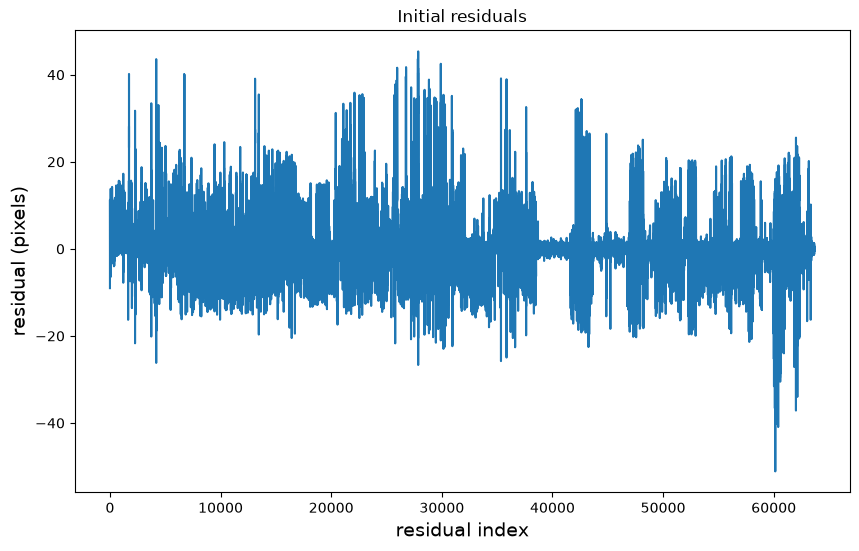

In [5]:
def project(T, k, X):
    P = T[:3, :3] @ X + T[:3, 3]
    p = -P[:2] / P[2]
    n = (p * p).sum()
    return k[0] * (1 + k[1] * n + k[2] * n * n) * p


def residuals(x):
    T, k, X = unpack(x)
    cam_idx, pt_idx, uv = observations(x)
    return torch.vmap(project)(T[cam_idx], k[cam_idx], X[pt_idx]) - uv


def cost(x):
    r = residuals(x)
    return 0.5 * (r * r).sum()


r0 = residuals(x0)
print(f"initial cost: {cost(x0).item():.6g}")
plt.plot(r0.reshape(-1))
plt.xlabel("residual index")
plt.ylabel("residual (pixels)")
plt.title("Initial residuals");

## Sparse normal equations on the manifold

`piazzi.least_squares` builds a dense Jacobian, which is out of the question here ($63\,686 \times 23\,769$). Instead we write the `system(x) -> (loss, g, H)` that `piazzi.gauss_newton` expects, with a sparse `H`.

Residual $i$ depends only on camera $c_i$ and point $p_i$. Following the manifold recipe, its Jacobian is that of

$$
\boldsymbol\delta \mapsto \text{project}\big(\text{plus}(T_{c_i}, \boldsymbol\delta_T),\; \mathbf{k}_{c_i} + \boldsymbol\delta_k,\; \mathbf{X}_{p_i} + \boldsymbol\delta_X\big) - \mathbf{u}_i
$$

at $\boldsymbol\delta = 0$: a $2 \times 12$ block, computed for all observations at once with `torch.func.jacfwd` inside `torch.vmap`, through `pose.plus`. The normal equations have the classic bundle-adjustment structure

$$
H = J^\top J = \begin{bmatrix} U & W \\ W^\top & V \end{bmatrix},
$$

with $9 \times 9$ camera blocks $U$ and $3 \times 3$ point blocks $V$ on the diagonal, and a $9 \times 3$ block of $W$ for every observation. We assemble it as a sparse COO tensor.

In [6]:
def observation_residual(T, k, X, u, d_pose, d_k, d_X):
    return project(pose.plus(T, d_pose), k + d_k, X + d_X) - u


observation_jacobian = torch.vmap(
    torch.func.jacfwd(observation_residual, argnums=(4, 5, 6)), in_dims=(0, 0, 0, 0, None, None, None)
)


def block_indices(starts, rows, cols):
    # Row and column indices of dense blocks of shape (rows, cols) whose top-left corners are `starts`.
    dev = starts[0].device
    r = starts[0][:, None, None] + torch.arange(rows, device=dev)[None, :, None]
    c = starts[1][:, None, None] + torch.arange(cols, device=dev)[None, None, :]
    return r.expand(-1, rows, cols).reshape(-1), c.expand(-1, rows, cols).reshape(-1)


def system(x):
    T, k, X = unpack(x)
    cam_idx, pt_idx, uv = observations(x)
    kw = {"device": x.device, "dtype": x.dtype}
    zeros6, zeros3 = torch.zeros(6, **kw), torch.zeros(3, **kw)
    J_pose, J_k, J_X = observation_jacobian(T[cam_idx], k[cam_idx], X[pt_idx], uv, zeros6, zeros3, zeros3)
    J_cam = torch.cat([J_pose, J_k], -1)  # (n_observations, 2, 9)
    r = residuals(x)
    g_cam = torch.zeros(n_cameras, 9, **kw).index_add_(0, cam_idx, (J_cam.mT @ r[..., None])[..., 0])
    g_pt = torch.zeros(n_points, 3, **kw).index_add_(0, pt_idx, (J_X.mT @ r[..., None])[..., 0])
    U = torch.zeros(n_cameras, 9, 9, **kw).index_add_(0, cam_idx, J_cam.mT @ J_cam)
    V = torch.zeros(n_points, 3, 3, **kw).index_add_(0, pt_idx, J_X.mT @ J_X)
    W = J_cam.mT @ J_X  # (n_observations, 9, 3): one block per observation
    cam0 = 9 * torch.arange(n_cameras, device=x.device)
    pt0 = n_cam_dof + 3 * torch.arange(n_points, device=x.device)
    obs_cam0, obs_pt0 = 9 * cam_idx, n_cam_dof + 3 * pt_idx
    rU, cU = block_indices((cam0, cam0), 9, 9)
    rV, cV = block_indices((pt0, pt0), 3, 3)
    rW, cW = block_indices((obs_cam0, obs_pt0), 9, 3)
    rows = torch.cat([rU, rV, rW, cW])
    cols = torch.cat([cU, cV, cW, rW])
    vals = torch.cat([U.reshape(-1), V.reshape(-1), W.reshape(-1), W.reshape(-1)])
    n = n_cam_dof + 3 * n_points
    H = torch.sparse_coo_tensor(torch.stack([rows, cols]), vals, (n, n), check_invariants=False).coalesce()
    return 0.5 * (r * r).sum(), torch.cat([g_cam.reshape(-1), g_pt.reshape(-1)]), H


t = time.perf_counter()
loss, g, H = system(x0)
print(f"system built in {time.perf_counter() - t:.2f} s")
print(f"H: {H.shape[0]} x {H.shape[1]}, {H._nnz()} nonzeros ({100 * H._nnz() / H.shape[0] ** 2:.3f} % dense)")

system built in 2.47 s
H: 23769 x 23769, 1793475 nonzeros (0.317 % dense)


The sparsity pattern of $H$, on a coarse grid (a dot wherever a cell holds a nonzero). The camera block is the thin band at the top left; the point blocks form the diagonal; the observations fill the borders.

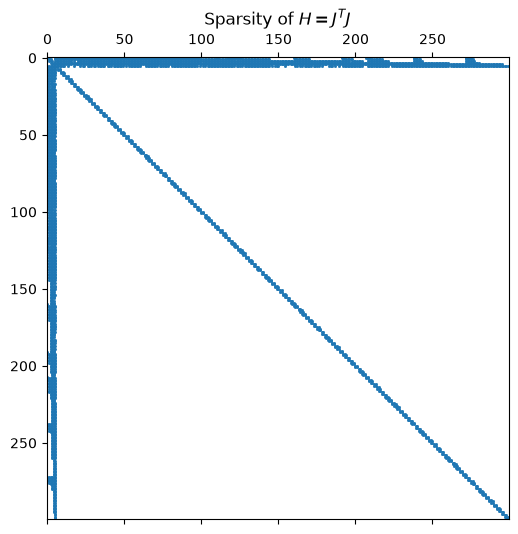

In [7]:
bins = 300
rows, cols = H.indices()
occupied = torch.zeros(bins, bins, dtype=torch.bool)
occupied[rows * bins // H.shape[0], cols * bins // H.shape[1]] = True
plt.figure(figsize=(6, 6))
plt.spy(occupied.numpy(), markersize=1)
plt.title("Sparsity of $H = J^T J$");

## Solving with conjugate gradients (torchsparsegradutils)

Given a sparse `H`, `piazzi.gauss_newton` solves the damped normal equations with `piazzi.cg_solver()` by default: Jacobi-preconditioned conjugate gradients from torchsparsegradutils, which only needs matrix-vector products with `H`. The solve is inexact, which Levenberg-Marquardt tolerates: its gain ratio checks every step.

Two settings matter for this problem:

- `damping="marquardt"` scales the damping by `diag(H)`, as Ceres does. The parameters have very different scales (focal lengths in the hundreds, distortion coefficients, poses and points), and plain `lam * I` damping makes much slower progress. It plays the role of `x_scale="jac"` in the cookbook.
- `max_step` caps every tangent coordinate per step; its default of 1 is too small for focal lengths in pixels, so we raise it.

The cookbook stops when the cost decreases by less than `ftol = 1e-4` (relative) in an iteration. `piazzi` has no `ftol`, but a callback can implement it.

Iterations are a poor measure of cost: solvers spend different numbers of evaluations per iteration, and the evaluations differ in price. The callback therefore also records the evaluations so far (`IterationInfo` carries them by kind), turned into one cost in units of a residual evaluation, as in the [Rosenbrock notebook](rosenbrock.ipynb):

- the residuals alone (a `value_fun` evaluation, used after a rejected step) cost 1;
- the residuals with their Jacobian (a `system` evaluation) cost $1 + 12 = 13$: forward-mode autodiff propagates one tangent per parameter a residual depends on, and each observation depends on 12 (6 for the pose, 3 intrinsics and 3 for the point), whatever the total number of parameters;
- SciPy's finite-difference Jacobian costs one residual evaluation per group of structurally independent columns, 20 for this sparsity pattern. We count those calls directly.

These are rules of thumb that ignore the cost of assembling and solving the normal equations, which the timings below include.

In [8]:
JACOBIAN_COST = 1 + 12  # forward mode: one tangent per parameter of an observation


def evaluations(counts):
    # Cost of the evaluations in an IterationInfo or OptimizeResult, in residual evaluations.
    return counts.n_fun + JACOBIAN_COST * counts.n_system


def make_ftol_callback(ftol, history):
    def callback(info):
        if info.accepted:
            history.append((evaluations(info), info.fun.item()))
        return info.accepted and (info.fun_start - info.fun).item() < ftol * info.fun_start.item()

    return callback


runs = {}


def run(name, x_start=x0, **kwargs):
    history = [(0, cost(x_start).item())]
    t = time.perf_counter()
    res = piazzi.gauss_newton(
        system,
        x_start,
        manifold=manifold,
        value_fun=cost,
        damping="marquardt",
        max_step=1e3,
        max_iter=50,
        callback=make_ftol_callback(1e-4, history),
        **kwargs,
    )
    elapsed = time.perf_counter() - t
    runs[name] = {"result": res, "history": history, "time": elapsed}
    print(
        f"{name}: cost {res.fun.item():.6g} after {res.n_iter} iterations ({evaluations(res)} residual evaluations),"
        f" {elapsed:.1f} s ({res.message})"
    )
    return res


res_cg = run("piazzi LM + CG", linear_solver=piazzi.cg_solver(tol=1e-3, max_iter=100))

piazzi LM + CG: cost 13425.2 after 25 iterations (338 residual evaluations), 33.6 s (stopped by callback)


## Solving with the Schur complement

CG ignores the structure of $H$. Bundle-adjustment solvers instead eliminate the points: block elimination of

$$
\begin{bmatrix} U & W \\ W^\top & V \end{bmatrix}
\begin{bmatrix} \boldsymbol\delta_c \\ \boldsymbol\delta_p \end{bmatrix}
= -\begin{bmatrix} \mathbf{g}_c \\ \mathbf{g}_p \end{bmatrix}
$$

(with the damping already added to the diagonal) gives the reduced camera system

$$
(U - W V^{-1} W^\top)\,\boldsymbol\delta_c = -\mathbf{g}_c + W V^{-1} \mathbf{g}_p,
\qquad
\boldsymbol\delta_p = -V^{-1}(\mathbf{g}_p + W^\top \boldsymbol\delta_c).
$$

$V$ is block diagonal, so $V^{-1}$ is cheap, and the reduced system is only $441 \times 441$: it is solved exactly with a dense Cholesky factorisation. A `linear_solver` receives `(H, g, damping)` and returns the step, so the Schur solver reads the blocks straight from the sparse `H`. It runs on whatever device `H` is on.

In [9]:
def schur_solver(n_reduced, block=3):
    # Eliminates the block-diagonal trailing part of H (blocks of size `block`), then solves
    # the dense reduced system for the first `n_reduced` unknowns.

    def solve(H, g, damping):
        dev, dt, n = H.device, H.dtype, H.shape[0]
        diag = torch.arange(n, device=dev)
        H = (
            H + torch.sparse_coo_tensor(torch.stack([diag, diag]), damping, H.shape, check_invariants=False)
        ).coalesce()
        (r, c), v = H.indices(), H.values()
        n_pt = (n - n_reduced) // block
        top, left = r < n_reduced, c < n_reduced
        m = top & left
        U = torch.zeros(n_reduced, n_reduced, device=dev, dtype=dt).index_put_((r[m], c[m]), v[m], accumulate=True)
        m = top & ~left
        W = torch.sparse_coo_tensor(
            torch.stack([r[m], c[m] - n_reduced]), v[m], (n_reduced, n - n_reduced), check_invariants=False
        )
        m = ~top & ~left
        rr, cc = r[m] - n_reduced, c[m] - n_reduced
        assert torch.equal(rr // block, cc // block), "the trailing part of H must be block diagonal"
        V = torch.zeros(n_pt, block, block, device=dev, dtype=dt)
        V.index_put_((rr // block, rr % block, cc % block), v[m], accumulate=True)
        V_inv = torch.linalg.inv(V)
        # V^-1 as a sparse block-diagonal matrix. Only sparse @ dense products are used below:
        # sparse @ sparse is slow on MPS (and goes through CSR, a beta layout, on the CPU).
        starts = block * torch.arange(n_pt, device=dev)
        rV, cV = block_indices((starts, starts), block, block)
        V_inv_sparse = torch.sparse_coo_tensor(
            torch.stack([rV, cV]), V_inv.reshape(-1), (n - n_reduced,) * 2, check_invariants=False
        )
        Z = V_inv_sparse @ W.t().to_dense()  # V^-1 W^T, dense (n - n_reduced) x n_reduced
        S = U - W @ Z
        g_c, g_p = g[:n_reduced], g[n_reduced:]
        rhs = -g_c + Z.T @ g_p
        L, info = torch.linalg.cholesky_ex(S)
        # In float32, rounding can make S numerically indefinite; fall back to LU then.
        d_c = torch.cholesky_solve(rhs[:, None], L)[:, 0] if info.item() == 0 else torch.linalg.solve(S, rhs)
        d_p = -(V_inv @ (g_p + W.t() @ d_c).reshape(n_pt, block, 1)).reshape(-1)
        return torch.cat([d_c, d_p])

    return solve


res_schur = run("piazzi LM + Schur", linear_solver=schur_solver(n_cam_dof))

piazzi LM + Schur: cost 13351.9 after 17 iterations (234 residual evaluations), 4.3 s (stopped by callback)


## SciPy reference

The cookbook's solution, for comparison: `scipy.optimize.least_squares` with the trust-region reflective method, finite-difference Jacobians on the given sparsity pattern, Jacobian scaling and `ftol=1e-4`. It works on the rotation-vector parametrisation of the BAL file. We count every call to the residual function, finite differences included, and record the cost after each iteration with SciPy's `callback` (SciPy 1.16 or later; with an older SciPy, only the final point is plotted).

In [10]:
from scipy.optimize import least_squares
from scipy.sparse import lil_matrix
from scipy.spatial.transform import Rotation


def project_np(points, camera_params):
    p = Rotation.from_rotvec(camera_params[:, :3]).apply(points) + camera_params[:, 3:6]
    p = -p[:, :2] / p[:, 2, np.newaxis]
    f, k1, k2 = camera_params[:, 6], camera_params[:, 7], camera_params[:, 8]
    n = np.sum(p**2, axis=1)
    return p * (f * (1 + k1 * n + k2 * n**2))[:, np.newaxis]


def fun_np(params):
    cams = params[: n_cameras * 9].reshape((n_cameras, 9))
    pts = params[n_cameras * 9 :].reshape((n_points, 3))
    return (project_np(pts[point_indices], cams[camera_indices]) - points_2d).ravel()


def bundle_adjustment_sparsity():
    m, n = camera_indices.size * 2, n_cameras * 9 + n_points * 3
    A = lil_matrix((m, n), dtype=int)
    i = np.arange(camera_indices.size)
    for s in range(9):
        A[2 * i, camera_indices * 9 + s] = 1
        A[2 * i + 1, camera_indices * 9 + s] = 1
    for s in range(3):
        A[2 * i, n_cameras * 9 + point_indices * 3 + s] = 1
        A[2 * i + 1, n_cameras * 9 + point_indices * 3 + s] = 1
    return A


x0_np = np.hstack((camera_params.ravel(), points_3d.ravel()))
n_calls = 0


def counted_fun_np(params):
    global n_calls
    n_calls += 1
    return fun_np(params)


scipy_history = [(0, 0.5 * np.sum(fun_np(x0_np) ** 2))]
kwargs = {}
if "callback" in inspect.signature(least_squares).parameters:  # SciPy >= 1.16
    kwargs["callback"] = lambda intermediate_result: scipy_history.append(
        (n_calls, 0.5 * np.sum(intermediate_result.fun**2))
    )
t = time.perf_counter()
res_scipy = least_squares(
    counted_fun_np, x0_np, jac_sparsity=bundle_adjustment_sparsity(), x_scale="jac", ftol=1e-4, method="trf", **kwargs
)
elapsed = time.perf_counter() - t
if scipy_history[-1][0] != n_calls:
    scipy_history.append((n_calls, res_scipy.cost))
runs["scipy TRF"] = {"history": scipy_history, "time": elapsed, "evaluations": n_calls}
print(
    f"scipy TRF: cost {res_scipy.cost:.6g} after {res_scipy.njev} Jacobians and {res_scipy.nfev} other residual"
    f" evaluations ({n_calls} residual evaluations in all), {elapsed:.1f} s"
)

scipy TRF: cost 13408.9 after 13 Jacobians and 15 other residual evaluations (275 residual evaluations in all), 8.9 s


## Comparison

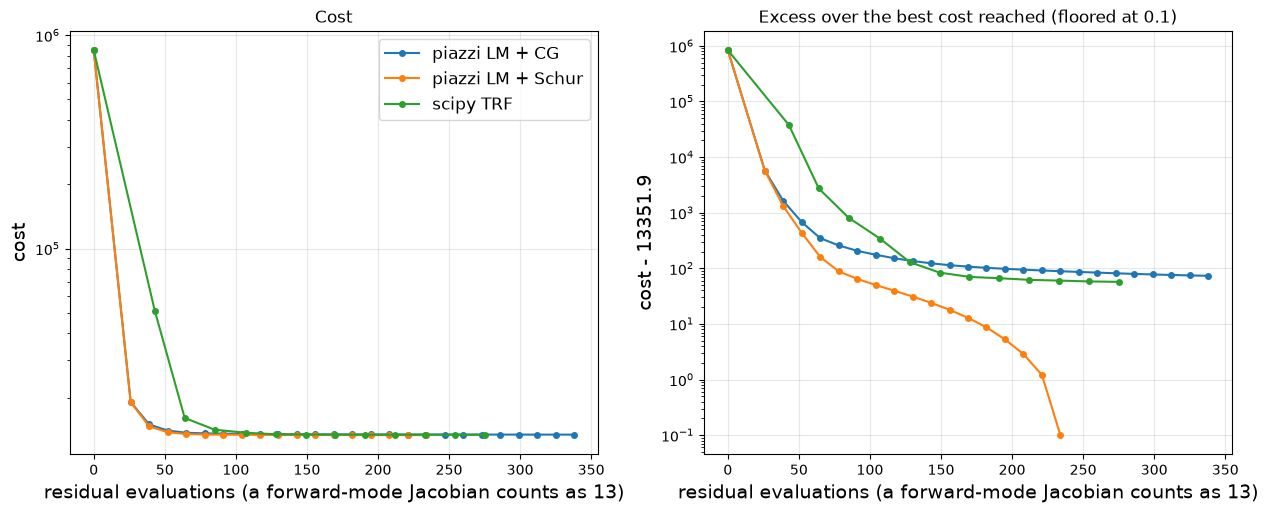

In [11]:
best = min(c for run_ in runs.values() for _, c in run_["history"])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
for name, run_ in runs.items():
    evals, costs = map(np.array, zip(*run_["history"], strict=True))
    ax1.semilogy(evals, costs, "o-", ms=4, label=name)
    ax2.semilogy(evals, np.maximum(costs - best, 1e-1), "o-", ms=4, label=name)
for ax in (ax1, ax2):
    ax.set_xlabel("residual evaluations (a forward-mode Jacobian counts as 13)")
    ax.grid(True, which="major", alpha=0.3)
ax1.set_ylabel("cost")
ax1.set_title("Cost")
ax2.set_ylabel(f"cost - {best:.1f}")
ax2.set_title("Excess over the best cost reached (floored at 0.1)")
ax1.legend();

In [12]:
print(f"{'solver':20s} {'cost':>10s} {'residual evaluations':>21s} {'time (s)':>9s}")
for name, run_ in runs.items():
    if "result" in run_:
        final, n_evals = run_["result"].fun.item(), evaluations(run_["result"])
    else:
        final, n_evals = res_scipy.cost, run_["evaluations"]
    print(f"{name:20s} {final:10.6g} {n_evals:21d} {run_['time']:9.1f}")

solver                     cost  residual evaluations  time (s)
piazzi LM + CG          13425.2                   338      33.6
piazzi LM + Schur       13351.9                   234       4.3
scipy TRF               13408.9                   275       8.9


All three runs land on solutions of essentially the same quality, about 64 times below the initial cost; the right panel shows how they differ near the end.

- Levenberg-Marquardt with the Schur solver gets the exact damped step. It reaches SciPy's final cost after about 100 residual evaluations, under 40 % of SciPy's 275, and keeps improving until the `ftol` test stops it. Part of the gap is the price of a Jacobian (13 evaluations in forward mode against 20 for SciPy's finite differences), and part is that its early steps make more progress.
- SciPy's trust-region reflective method makes less progress on its first iteration (a cost of about 51,000 after 43 evaluations, against 19,000 after 26 for piazzi), and its `ftol` test stops it about 57 above the best cost.
- CG solves each damped system only approximately (100 iterations on the ill-conditioned full system), so its steps lose ground near the end and it stops about 70 above the best cost. Its advantage is that it needs nothing but `H` itself. It is also the slowest in wall-clock time, since each CG iteration multiplies by the 1.8-million-entry `H`; the evaluation count does not include that work.

Every pose stayed a rigid transform: the manifold only ever composes it with rotations and translations. For use with BAL tools, the poses convert back to rotation vectors with `piazzi.so3_log`.

max |R^T R - I|: 1.7763568394002505e-15
max |det R - 1|: 1.1102230246251565e-15
cost of the piazzi solution evaluated by the SciPy model: 13351.9


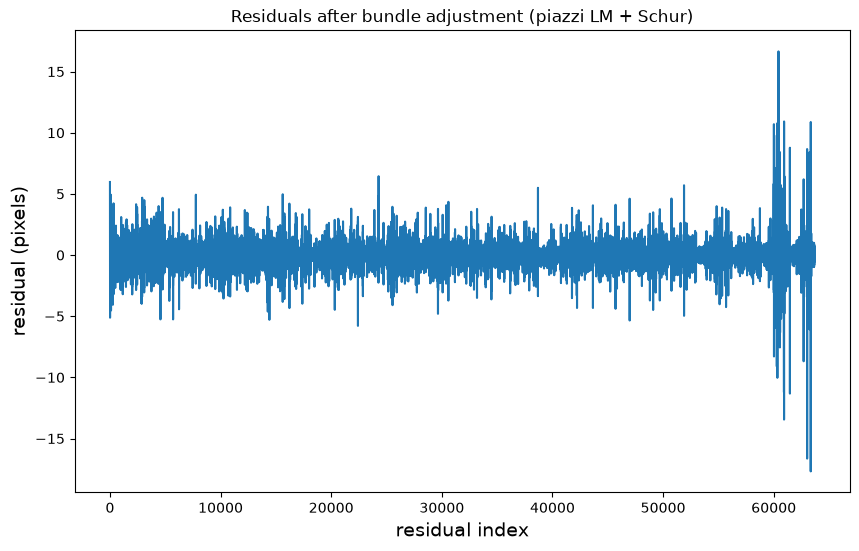

In [13]:
T, k, X = unpack(res_schur.x)
R = T[:, :3, :3]
print("max |R^T R - I|:", (R.mT @ R - torch.eye(3)).abs().max().item())
print("max |det R - 1|:", (torch.linalg.det(R) - 1).abs().max().item())

camera_params_opt = torch.cat([piazzi.so3_log(R), T[:, :3, 3], k], 1)
x_opt_np = np.hstack((camera_params_opt.numpy().ravel(), X.numpy().ravel()))
print(f"cost of the piazzi solution evaluated by the SciPy model: {0.5 * np.sum(fun_np(x_opt_np) ** 2):.6g}")

plt.plot(residuals(res_schur.x).reshape(-1))
plt.xlabel("residual index")
plt.ylabel("residual (pixels)")
plt.title("Residuals after bundle adjustment (piazzi LM + Schur)");

## On a GPU: float32 Jacobians, with the solve on the CPU or on the GPU

Every function above follows the device and dtype of `x`, so the same code runs on a GPU: move `x0` there. GPUs are fast in float32 but slow (CUDA consumer cards) or unable (Apple MPS) in float64, so we compare two splits:

1. **Jacobians on the GPU, solve on the CPU.** The residuals, the Jacobians and the sparse `H` are computed in float32 on the GPU. `gauss_newton` then moves only `g` and `H` to `solve_device` and solves in `solve_dtype`, by default the CPU in float64, and moves the step back. This is the default: nothing changes but the device of `x0`.
2. **Everything on the GPU.** `solve_device=device, solve_dtype=torch.float32` keeps the linear solver on the GPU too.

On Apple MPS, PyTorch (2.15) supports sparse COO tensors and sparse @ dense products, but not CSR tensors or float64. The Schur solver therefore uses COO and only sparse @ dense products. Without a GPU, the cells below run the same code in float32 on the CPU.

In [14]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"  # no GPU: run the same float32 code on the CPU


def synchronize():
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()


def time_system(x, repeats=5):
    system(x)  # warm up (kernel compilation, first forward-mode AD call)
    synchronize()
    t = time.perf_counter()
    for _ in range(repeats):
        system(x)
    synchronize()
    return (time.perf_counter() - t) / repeats * 1e3


x0_32 = x0.to(device=device, dtype=torch.float32)
print(f"device: {device}")
print(f"system: {time_system(x0_32):.0f} ms on {device} in float32, {time_system(x0):.0f} ms on the CPU in float64")

device: mps


system: 30 ms on mps in float32, 83 ms on the CPU in float64


In [15]:
on_device = {"solve_device": device, "solve_dtype": torch.float32}
res_gpu_cpu = run(f"{device} f32 + CPU f64 Schur", x_start=x0_32, linear_solver=schur_solver(n_cam_dof))
res_gpu_schur = run(f"{device} f32 Schur", x_start=x0_32, linear_solver=schur_solver(n_cam_dof), **on_device)
res_gpu_cg = run(f"{device} f32 CG", x_start=x0_32, linear_solver=piazzi.cg_solver(tol=1e-3, max_iter=100), **on_device)

mps f32 + CPU f64 Schur: cost 13351.9 after 17 iterations (234 residual evaluations), 3.7 s (stopped by callback)


mps f32 Schur: cost 13351.9 after 20 iterations (275 residual evaluations), 1.7 s (stopped by callback)


mps f32 CG: cost 13425.6 after 25 iterations (338 residual evaluations), 7.3 s (stopped by callback)


In [16]:
print(f"{'run':28s} {'iterations':>10s} {'evals':>6s} {'cost (float64)':>15s} {'time (s)':>9s} {'s/iteration':>12s}")
for name, run_ in runs.items():
    if "result" not in run_:  # the SciPy run
        continue
    res = run_["result"]
    final = cost(res.x.cpu().to(torch.float64)).item()  # re-evaluated in float64 on the CPU
    n_evals = evaluations(res)
    print(
        f"{name:28s} {res.n_iter:10d} {n_evals:6d} {final:15.6g} {run_['time']:9.1f} {run_['time'] / res.n_iter:12.2f}"
    )
T32 = unpack(res_gpu_schur.x.cpu().to(torch.float64))[0]
print("max |R^T R - I| after the float32 run:", (T32[:, :3, :3].mT @ T32[:, :3, :3] - torch.eye(3)).abs().max().item())

run                          iterations  evals  cost (float64)  time (s)  s/iteration
piazzi LM + CG                       25    338         13425.2      33.6         1.35
piazzi LM + Schur                    17    234         13351.9       4.3         0.25
mps f32 + CPU f64 Schur              17    234         13351.9       3.7         0.22
mps f32 Schur                        20    275         13351.8       1.7         0.09
mps f32 CG                           25    338         13425.6       7.3         0.29
max |R^T R - I| after the float32 run: 7.9510388140136e-07


float32 is accurate enough here: the GPU runs reach the same cost as the float64 runs, to about 1e-4 relative, and the poses stay rigid to float32 precision (the SE(3) update multiplies a rigid transform by an exactly built rotation, so errors do not accumulate beyond rounding). The float32 runs can take a few more iterations, because each step is slightly less exact and the `ftol` test sees float32 noise.

What pays off depends on where the time goes:

- With the Schur solver on the CPU, the solve dominates each iteration, so moving only the Jacobians to the GPU gains little.
- With everything on the GPU, both solvers speed up: the Schur solver's sparse @ dense products and the 441 x 441 Cholesky are fast there, and CG is dominated by sparse matrix-vector products, which the GPU runs several times faster than the CPU.
- The manifold update `manifold.plus` loops over the 98 camera blocks of the `Product` and launches many small kernels; it costs a few milliseconds per iteration on the CPU and more on a GPU, but stays small next to the rest.